В файле insurance.csv представлены данные о стоимости медицинской страховки в зависимости от комбинации различных факторов. 

Исследовались переменные:
age: возраст (количественная)
sex: пол (категориальная: male/female)
bmi: индекс массы тела (количественная)
children: количество детей/иждивенцев (дискретная количественная)
smoker: курит ли (категориальная: yes/no)
region: регион (категориальная: southwest/southeast/northwest/northeast)
charges: стоимость страховки.

1. Установить три переменные, имеющие наибольшую корреляционную связь со стоимостью медицинской страховки (charges).
Для количественных переменных сравнить значения различных коэффициентов корреляции. 
Проверить значимость коэффициентов корреляции. 
Построить корреляционную матрицу для всех количественных переменных.

In [27]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
#import seaborn as sns

df = pd.read_csv('insurance.csv')

In [3]:
df_metric = df.copy()
df_metric['smoker'] = df_metric['smoker'].map({'yes': 1, 'no': 0})
df_metric['sex'] = df_metric['sex'].map({'male': 1, 'female': 0})

corr_top_3 = df_metric.corr(numeric_only=True)['charges'].abs().sort_values(ascending=False)[1:4]
print("три переменные, имеющие наибольшую корреляционную связь с charges:\n", corr_top_3)

три переменные, имеющие наибольшую корреляционную связь с charges:
 smoker    0.787251
age       0.299008
bmi       0.198341
Name: charges, dtype: float64


In [7]:
quant_vars = ['age', 'bmi', 'children']

for var in quant_vars:
    p_corr, p_value = stats.pearsonr(df[var], df['charges'])
    s_corr, p_value = stats.spearmanr(df[var], df['charges'])
    k_corr, p_value = stats.kendalltau(df[var], df['charges'])

    print(f"\n{var}:")
    print(f" Пирсон: {p_corr:.3f} (p={p_value:.2e})")
    print(f" Спирмен: {s_corr:.3f} (p={p_value:.2e})")
    print(f" Кендалл: {k_corr:.3f} (p={p_value:.2e})")


age:
 Пирсон: 0.299 (p=2.59e-146)
 Спирмен: 0.534 (p=2.59e-146)
 Кендалл: 0.475 (p=2.59e-146)

bmi:
 Пирсон: 0.198 (p=6.26e-06)
 Спирмен: 0.119 (p=6.26e-06)
 Кендалл: 0.083 (p=6.26e-06)

children:
 Пирсон: 0.068 (p=5.03e-07)
 Спирмен: 0.133 (p=5.03e-07)
 Кендалл: 0.103 (p=5.03e-07)


In [9]:
corr_matrix = df[['age', 'bmi', 'children', 'charges']].corr()
print("Матрица корреляции\n", corr_matrix)

Матрица корреляции
                age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000


2. Установить наличие корреляционной связи между полом (sex) и курением (smoke)

In [12]:
# таблица сопряженности
cross_tab = pd.crosstab(df['sex'], df['smoker'])
print(cross_tab)

chi2, p, dof, expected = stats.chi2_contingency(cross_tab)

print("\nОжидаемые частоты:\n", expected)
print(f"\nХи-квадрат: {chi2:.4f}")
print(f"\np-value: {p:.4f}")

smoker   no  yes
sex             
female  547  115
male    517  159

Ожидаемые частоты:
 [[526.43348281 135.56651719]
 [537.56651719 138.43348281]]

Хи-квадрат: 7.3929

p-value: 0.0065


3. На основе однофакторного дисперсионного анализа выяснить, влияют ли:
1) фактор курения,
2) индекс массы тела,
3) возраст (разделить на 3 категории)
на стоимость медицинской страховки?

Сделать визуализацию распределения данных по группам на основе boxplot. 

Проверить выполнение требований для дынных, которые необходимы для проведения классического дисперсионного анализа.
Если требования не выполнены, все равно провести дисперсионный анализ.


 анализ фактора smoker
Проверка p > 0.05:
  группа no: p = 1.45e-28
  группа yes: p = 3.62e-09
Тест Левена: p = 1.56e-66
Результат ANOVA: F = 2177.6149, p-value = 8.27e-283
Фактор smoker статистически значимо влияет на цену страховки


<Figure size 800x600 with 0 Axes>

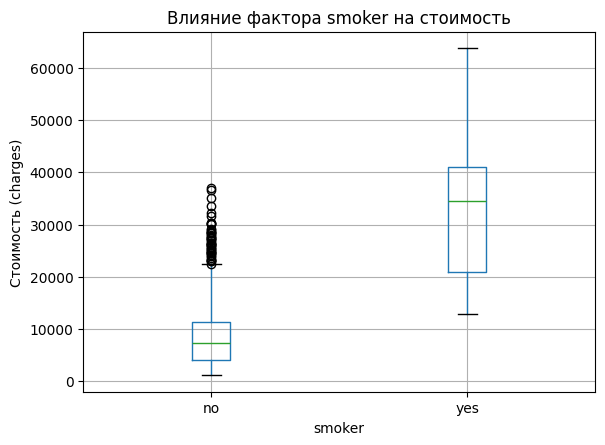


 анализ фактора bmi_categs
Проверка p > 0.05:
  группа Low: p = 7.13e-16
  группа Medium: p = 5.01e-22
  группа High: p = 9.58e-23
Тест Левена: p = 2.01e-13
Результат ANOVA: F = 25.7007, p-value = 1.12e-11
Фактор bmi_categs статистически значимо влияет на цену страховки


C:\Users\в\AppData\Local\Temp\ipykernel_19144\435613233.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = [group['charges'] for name, group in df.groupby(factor)]  # деленеие данных на группы для тестов
C:\Users\в\AppData\Local\Temp\ipykernel_19144\435613233.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for name, data in df.groupby(factor):


<Figure size 800x600 with 0 Axes>

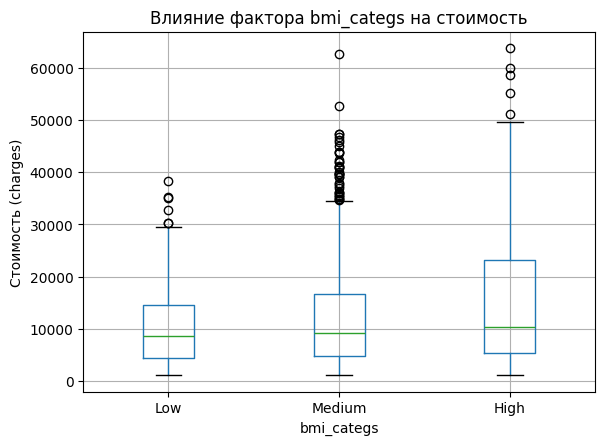


 анализ фактора age_categs
Проверка p > 0.05:
  группа Young: p = 1.98e-28
  группа Middle: p = 6.20e-27
  группа Old: p = 2.68e-27
Тест Левена: p = 8.46e-01
Результат ANOVA: F = 52.4487, p-value = 1.18e-22
Фактор age_categs статистически значимо влияет на цену страховки


C:\Users\в\AppData\Local\Temp\ipykernel_19144\435613233.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = [group['charges'] for name, group in df.groupby(factor)]  # деленеие данных на группы для тестов
C:\Users\в\AppData\Local\Temp\ipykernel_19144\435613233.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for name, data in df.groupby(factor):


<Figure size 800x600 with 0 Axes>

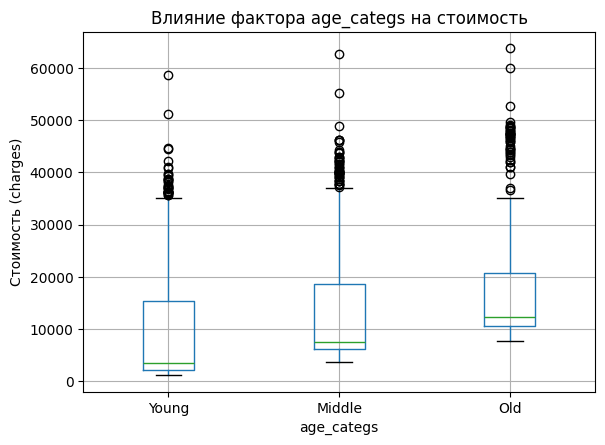

In [26]:
df['age_categs'] = pd.qcut(df['age'], q=3, labels=['Young', 'Middle', 'Old'])

df['bmi_categs'] = pd.qcut(df['bmi'], q=3, labels=['Low', 'Medium', 'High'])

factors = ['smoker', 'bmi_categs', 'age_categs']

for factor in factors:
    print(f"\n анализ фактора {factor}")
    
    groups = [group['charges'] for name, group in df.groupby(factor)]  # деленеие данных на группы для тестов

    # Тест Шапиро-Уилка на нормальность для каждой группы
    print("Проверка p > 0.05:")
    for name, data in df.groupby(factor):
        shapiro_p = stats.shapiro(data['charges'])[1]
        print(f"  группа {name}: p = {shapiro_p:.2e}")
        
    # Тест Левена на однородность дисперсий (равенство разброса)
    levene_p = stats.levene(*groups)[1]
    print(f"Тест Левена: p = {levene_p:.2e}")
    
    # Дисперсионный анализ (ANOVA)
    f_stat, p_anova = stats.f_oneway(*groups)
    print(f"Результат ANOVA: F = {f_stat:.4f}, p-value = {p_anova:.2e}")
    
    if p_anova < 0.05:
        print(f"Фактор {factor} статистически значимо влияет на цену страховки")
    else:
        print(f"Влияние фактора {factor} не подтверждено")

    plt.figure(figsize=(8, 6))
    df.boxplot(column='charges', by=factor, grid=True)
    
    plt.title(f'Влияние фактора {factor} на стоимость')
    plt.suptitle('')
    plt.ylabel('Стоимость (charges)')
    plt.xlabel(factor)
    
    plt.show()

